### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)
    os.makedirs(os.path.join(tmpdir, "chirp"))

/flash/ReiterU/tmp/tomo_BJRZPMHBMLQV


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import signal
import h5py
import cv2
from scipy import ndimage as ndi
from roifile import roiread
import scipy.spatial.distance as dist
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import matplotlib.patches as mpatches
from sklearn.decomposition import SparsePCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

import scanpy as sc
from anndata import AnnData
import leidenalg
import igraph as ig

In [4]:
import sys
sys.path.append("../../")
from calfuncs.io import read_sync_ttl
from calfuncs.full_field_step import plot_chirp_eta, compute_qi

sys.path.append("./")
from plot_functions import characterize_neurons, plot_index, plot_index2, plot_cluster_average, plot_clustering, plot_spca_features

In [5]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

### load data

In [6]:
with pd.HDFStore("/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden_merged/result_combined_merged.hdf5", mode='r') as store:
    R = store["R"]
    E = store["E"]

In [7]:
R_raw = R.copy()

In [8]:
display(R)

,recording,region,neuron,good,time_0,time_1,time_2,time_3,time_4,time_5,...,spca_20,spca_21,spca_22,spca_23,spca_24,spca_25,spca_26,spca_27,spca_28,spca_29
0,0,OGL,0,True,-0.508928,-0.464390,-0.466365,-0.342068,-0.295410,-0.459671,...,-3.923330,3.709491,-4.282827,-0.105844,2.921576,-2.371190,6.794475,1.638139,-1.561589,-2.704803
1,0,OGL,1,True,-0.257964,-0.253338,-0.456095,-0.514363,-0.351929,-0.346033,...,5.339304,-1.933449,1.602021,-1.236076,-1.521483,-0.380997,-4.370857,0.172448,1.170956,2.915614
2,0,OGL,2,True,-0.602118,-0.612503,-0.581508,-0.606921,-0.662248,-0.678898,...,-3.798328,-3.903314,-4.688595,2.911292,4.142401,2.702043,13.248385,-2.709772,-9.203449,-3.090206
3,0,OGL,3,True,0.563219,0.600015,0.847742,0.828184,0.842527,0.744541,...,9.482357,-2.478874,0.828057,-1.545227,-1.273875,-0.399481,-8.381687,-0.387511,2.143006,4.293992
4,0,OGL,4,True,0.572637,0.440795,0.267777,0.706606,0.556995,0.539196,...,-3.026185,0.599556,-1.176504,1.177105,-0.400154,-0.211736,6.968509,-0.774289,-3.296001,-1.535753
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2994,20,IGL,187,True,0.576814,0.268578,0.004038,0.212486,0.774889,0.519236,...,-0.940315,1.341109,-1.425903,-1.533258,1.292770,0.239178,-1.165633,-0.675126,2.866180,0.216316
2995,20,IGL,188,False,0.203239,0.787004,0.771219,0.418283,0.112171,-0.219562,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2996,20,IGL,189,False,0.226999,0.060144,0.330831,0.602990,0.920282,0.464031,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2997,20,IGL,190,True,-0.093924,-0.147579,-0.555467,-0.544272,-0.422625,-0.378776,...,-5.141545,-0.621915,10.703491,-2.334290,-0.142033,1.796851,1.115120,0.315398,-7.363258,-0.230249


In [9]:
display(E)

y
recording neuron session trial time            
0         0      0       0     -2000        NaN
                               -1950        NaN
                               -1900        NaN
                               -1850        NaN
                               -1800        NaN
...                                         ...
20        191    2       9      18750 -1.157461
                                18800 -2.285858
                                18850 -1.617408
                                18900 -0.432541
                                18950  0.188074

[45148320 rows x 1 columns]

### Plot

In [10]:
R3 = R[(R["good"])].copy()
R3.reset_index(inplace=True)
characterize_neurons(R3, E)

In [15]:
print(R3[R3["region"] == "OGL"].shape)
print(R3[R3["region"] == "IGL"].shape)
print(R3[R3["recording"] == 0].shape)

(1085, 1305)
(762, 1305)
(306, 1305)


Figure saved as /flash/ReiterU/tmp/tomo_BJRZPMHBMLQV/clustering.pdf


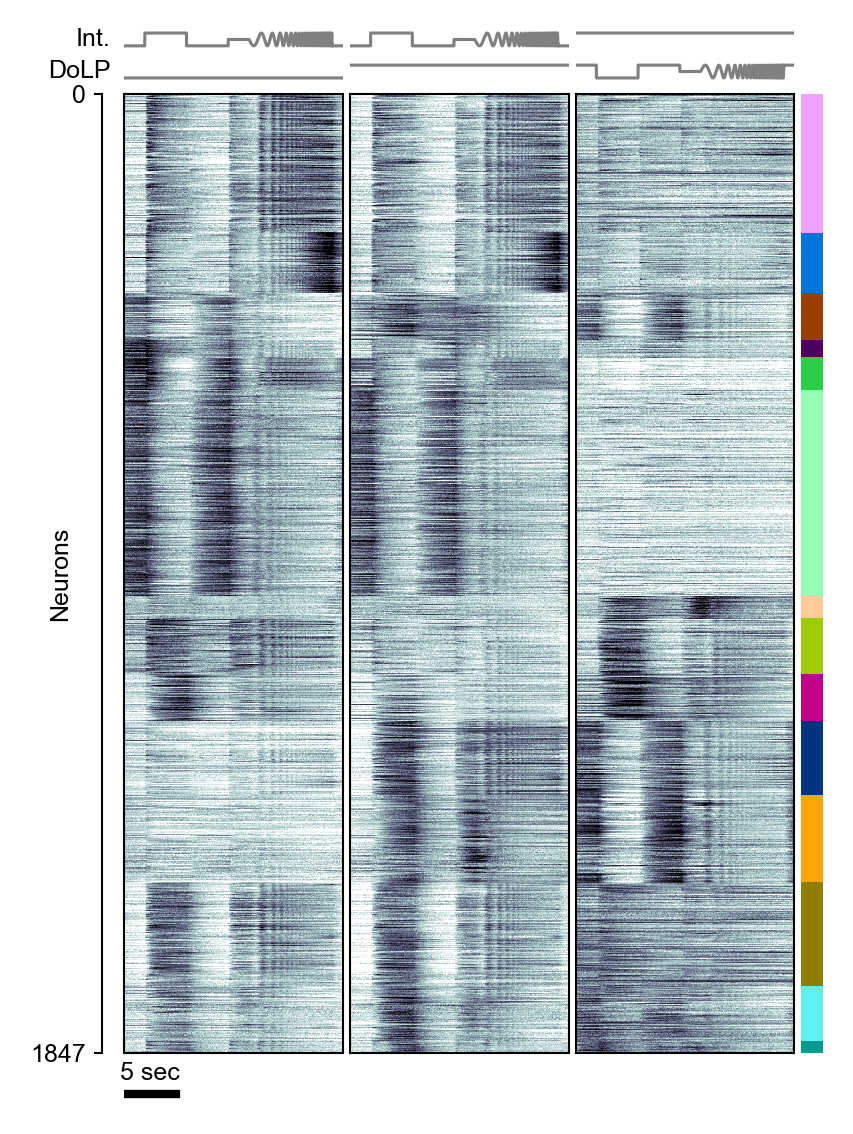

Figure saved as /flash/ReiterU/tmp/tomo_BJRZPMHBMLQV/cluster_mean.pdf


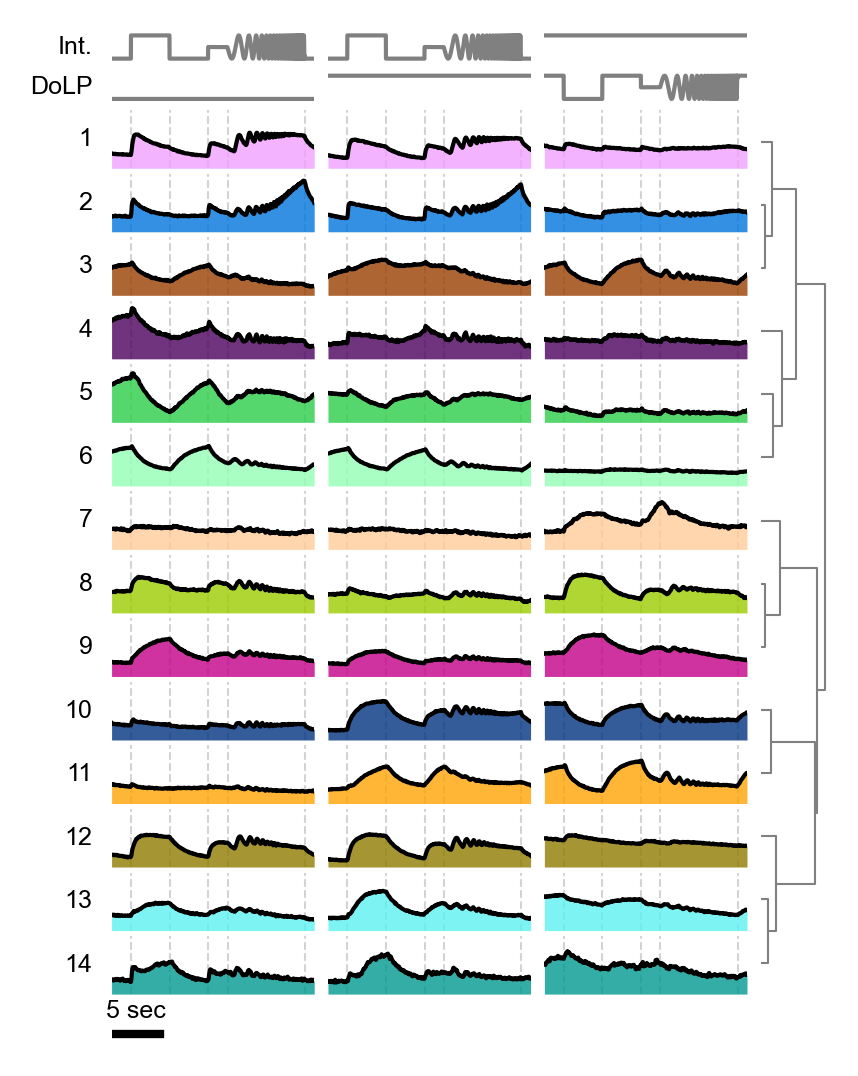

Figure saved as /flash/ReiterU/tmp/tomo_BJRZPMHBMLQV/spca_components.pdf


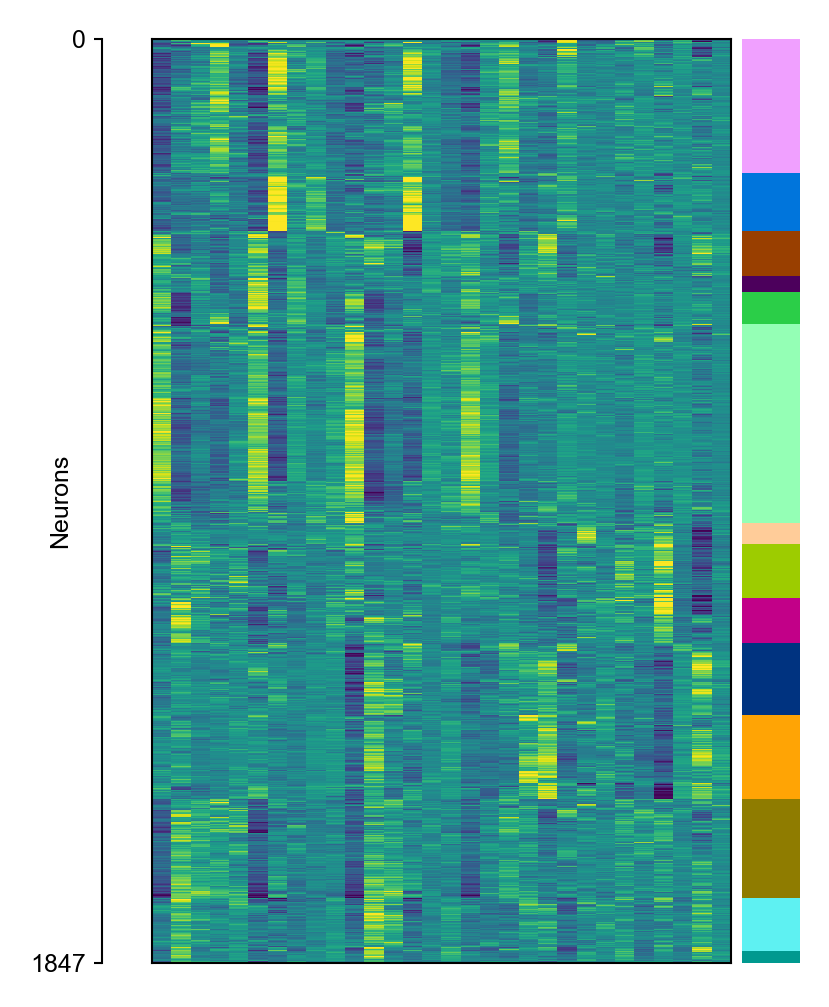

In [11]:
t = np.arange(21000) * 1e-3
stimulus = np.zeros_like(t)
stimulus[0:2000] = 0
stimulus[2000:6000] = 1
stimulus[6000:10000] = 0
stimulus[10000:12000] = 0.5
stimulus[12000:20000] = 0.5 + 0.5 * signal.chirp(np.linspace(0, 8, 8000), f0=0.5, f1=10, t1=8, method='logarithmic', phi=90)
stimulus[20000:21000] = 0

cluster_ids = R3["cluster"].sort_values().unique()

alphabet_colors = [
    "#F0A0FF", "#0075DC", "#993F00", "#4C005C",
    "#2BCE48", "#94FFB5", "#FFCC99", "#9DCC00",
    "#C20088", "#003380", "#FFA405", "#8F7C00", 
    "#5EF1F2", "#00998F", "#E0FF66", "#740AFF", "#990000", "#FFFF80",
    "#FFE100", "#FF5005", "#808080"
]
alphabet_cmap = mpl.colors.ListedColormap(alphabet_colors, name='alphabet')
color_map = {i: alphabet_cmap(i-1) for i in np.unique(cluster_ids).astype("int")}

with mpl.rc_context(rc={'font.size': 6, 'axes.titlesize': 6, 'legend.fontsize': 6}):
    plot_clustering(R3, color_map, stimulus, vmin=-1.0, vmax=2.2, colormap_name="bone_r", figsize=(3.1,4.65), figsavename=os.path.join(tmpdir, "clustering.pdf"))
    # plot_clustering(R3, color_map, stimulus, vmin=-1.0, vmax=2.2, colormap_name="bone_r", sort_within_cluster=True, figsize=(3.0,4.0), figsavename=os.path.join(tmpdir, "clustering.pdf"))
    plot_cluster_average(R3, color_map, stimulus, ymin=-1.5, ymax=2.5, figsize=(3.2,4.4), figsavename=os.path.join(tmpdir, "cluster_mean.pdf"))
    plot_spca_features(R3, color_map, vmin=-10, vmax=10, colormap_name="viridis", sort_within_cluster=True, figsize=(3.0,4.0), figsavename=os.path.join(tmpdir, "spca_components.pdf"))

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/cluster_index.pdf


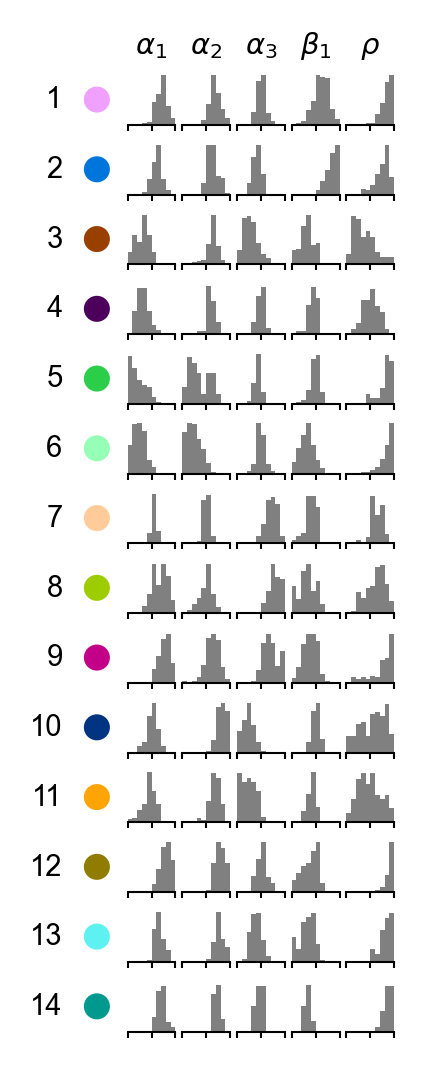

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/cluster_index2.pdf


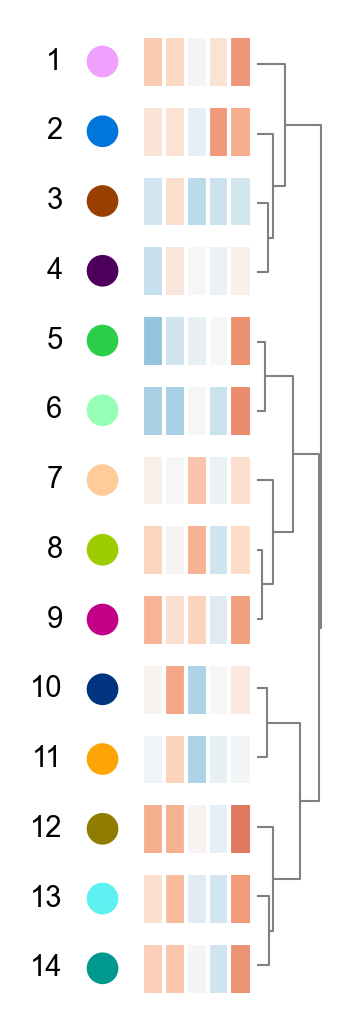

In [13]:
orig_cmap = plt.get_cmap('RdBu_r')
colors = orig_cmap(np.linspace(0.2, 0.8, 256))
new_cmap = mpl.colors.LinearSegmentedColormap.from_list('RdBu_r_trimmed', colors)
plot_index(R3, color_map, figsize=(1.4,4.2), figsavename=os.path.join(tmpdir, "cluster_index.pdf"))
plot_index2(R3, color_map, figsize=(1.1,4.2), cmap=new_cmap, figsavename=os.path.join(tmpdir, "cluster_index2.pdf"))

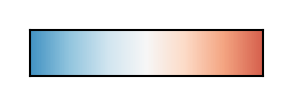

In [52]:
gradient = np.linspace(0, 1, 256).reshape(1, -1)
gradient = np.vstack([gradient] * 20)

fig, ax = plt.subplots(figsize=(1, 0.2), dpi=300)
ax.imshow(gradient, aspect='auto', cmap=new_cmap)
# ax.set_axis_off()
ax.set_xticks([])
ax.set_yticks([])
plt.savefig(os.path.join(tmpdir, "cutom_cmap_colormap.pdf"))
plt.show()

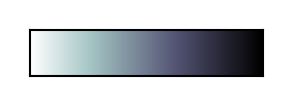

In [48]:
gradient = np.linspace(0, 1, 256).reshape(1, -1)
gradient = np.vstack([gradient] * 20)

fig, ax = plt.subplots(figsize=(1, 0.2), dpi=300)
ax.imshow(gradient, aspect='auto', cmap='bone_r')
# ax.set_axis_off()
ax.set_xticks([])
ax.set_yticks([])
plt.savefig(os.path.join(tmpdir, "bone_r_colormap.pdf"))
plt.show()

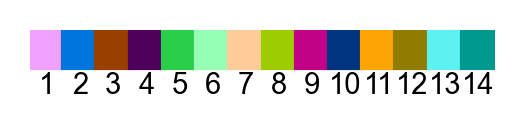

In [17]:
fig, ax = plt.subplots(figsize=(2, 0.2), dpi=300)
for i in range(1, len(color_map)+1):  # cmap.N is the number of colors in tab10 (10)
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=color_map[i]))
    ax.text(i + 0.5, -0.1, str(i), ha="center", va="top")
ax.set_xlim(1, len(color_map)+1)
ax.set_ylim(-0.2, 1)
ax.axis("off")
plt.savefig(os.path.join(tmpdir, "cluster_colormap.pdf"))
plt.show()

### UMAP visualization

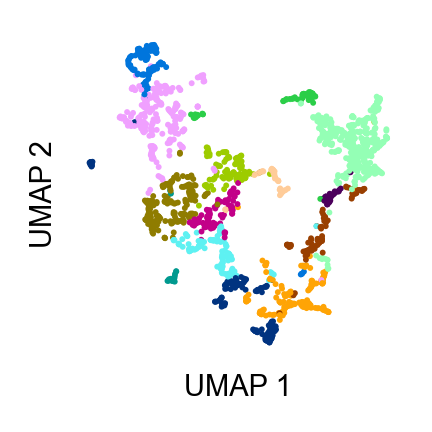

In [50]:
S = R3.filter(regex="^spca_").to_numpy()
adata = AnnData(S)
adata.obsm['X_spca'] = S

sc.pp.neighbors(adata, n_neighbors=5, metric='cosine', use_rep='X_spca', random_state=2025)
sc.tl.umap(adata, n_components=2, min_dist=0.05, spread=3.0)

fig, ax = plt.subplots(figsize=(1.45,1.45), dpi=300)
um = adata.obsm['X_umap']
point_colors = [color_map[e] for e in R3["cluster"]]
scatter = ax.scatter(um[:, 0], um[:, 1], c=point_colors, s=2, alpha=1, lw=0)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
ax.yaxis.set_inverted(True)
ax.xaxis.set_inverted(True)
for sp in ["top", "right", "bottom", "left"]:
    ax.spines[sp].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "umap.pdf"), bbox_inches='tight')
plt.show()

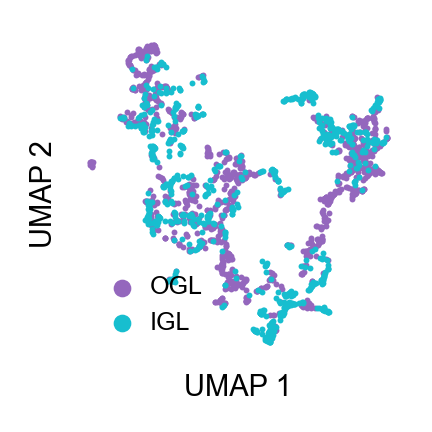

In [47]:
fig, ax = plt.subplots(figsize=(1.45,1.45), dpi=300)

um = adata.obsm['X_umap']
ogl_idx = R3[R3["region"] == "OGL"].index
igl_idx = R3[R3["region"] == "IGL"].index

ax.scatter(um[ogl_idx, 0], um[ogl_idx, 1], color='#9467bd', s=2, alpha=1, lw=0, label="OGL")
ax.scatter(um[igl_idx, 0], um[igl_idx, 1], color='#17becf', s=2, alpha=1, lw=0, label="IGL")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
ax.yaxis.set_inverted(True)
ax.xaxis.set_inverted(True)
for sp in ["top", "right", "bottom", "left"]:
    ax.spines[sp].set_visible(False)
ax.legend(frameon=False, loc="lower left", markerscale=3, fontsize=6, handletextpad=0.1)
plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "umap_region.pdf"), bbox_inches='tight')
plt.show()

Number of OGL neurons: 1085
Number of IGL neurons: 762


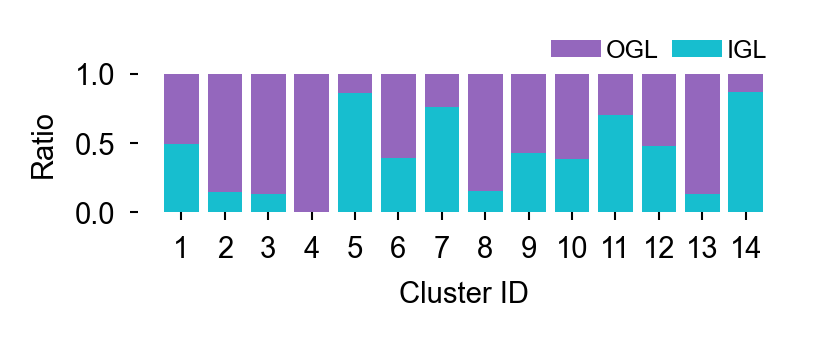

In [48]:
df1 = R3[R3["region"] == "OGL"]
df2 = R3[R3["region"] == "IGL"]
print("Number of OGL neurons:", df1.shape[0])
print("Number of IGL neurons:", df2.shape[0])

c1, c2 = [], []
for i in range(1, int(R3["cluster"].max())+1):
    c1.append(df1[df1["cluster"] == i].shape[0])
    c2.append(df2[df2["cluster"] == i].shape[0])
c1 = np.array(c1)
c2 = np.array(c2)

r1 = c1 / (c1 + c2)
r2 = c2 / (c1 + c2)
x = np.arange(1, r1.size + 1)

fig, ax = plt.subplots(figsize=(2.8,0.6), dpi=300)
ax.bar(x, r1, bottom=r2, width=0.8, color="#9467bd", label="OGL")
ax.bar(x, r2, width=0.8, color="#17becf", label="IGL")
ax.set_xlim(0, r1.size+1)
ax.set_ylim(0,1)
ax.set_xlabel("Cluster ID")
ax.set_ylabel("Ratio")
ax.set_xticks(np.arange(1, R3["cluster"].max()+1))
# ax.xaxis.set_tick_params(labelsize=6)
ax.legend(frameon=False, bbox_to_anchor=(0.6, 0.92), ncol=2, columnspacing=0.5, markerscale=1,  handletextpad=0.2, fontsize=6)
for sp in ["top", "right", "bottom", "left"]:
    ax.spines[sp].set_visible(False)

plt.savefig(os.path.join(tmpdir, "cluster_ratios.pdf"), bbox_inches='tight')
plt.show()

### Plot cells in a given cluster

In [15]:
def plot_chirp_eta(df, neuron_id, stimulus_train, vmin1=-1, vmax1=3, vmin2=-1, vmax2=3, cmap_name="bwr",
                   ylabels=True, figsize=(6,2.5), figsavename=None, show_plot=True):

    def _configure_axis(axis, show_ytick=False):
        if show_ytick:
            axis.set_yticks([0, 1])
        else:
            axis.set_yticks([])
        axis.set_xticks([])
        axis.set_xlim([t[0], t[-1]])
        axis.set_ylim([-0.25, 1.25])
        for sp in ["top", "right", "bottom", "left"]:
            axis.spines[sp].set_visible(False)

    t = df.index.get_level_values("time").unique()
    t /= 1000 # convert msec to sec

    # fig, axs = plt.subplots(4, 3, figsize=figsize, dpi=300, gridspec_kw={'height_ratios': [1, 1, 0.2, 0.2]})
    fig = plt.figure(figsize=figsize, dpi=300)
    gs = fig.add_gridspec(4, 3,
                          height_ratios=[0.2, 0.2, 0.8, 1.0],
                          wspace=0.1, hspace=0.15)

    for i in range(3):
        df_filtered = df.xs((i, neuron_id), level=["session", "neuron"])
        mat = df_filtered.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
        mat = mat[~np.all(np.isnan(mat), axis=1)]
        ax = fig.add_subplot(gs[2, i])
        ax.imshow(mat, vmin=vmin1, vmax=vmax1, cmap=cmap_name, aspect="auto", interpolation="nearest")
        if i == 0:
            if ylabels:
                ax.set_ylabel("Trials")
            else:
                ax.set_yticks([])
        else:
            ax.set_yticks([])
        ax.set_xticks([])

        mean = np.nanmean(mat, axis=0)
        error = np.nanstd(mat, axis=0)
        mean = ndi.uniform_filter1d(mean, size=3)
        error = ndi.uniform_filter1d(error, size=3)
        ax = fig.add_subplot(gs[3, i])
        ax.plot(t, mean, color="k", lw=1)
        ax.fill_between(t, mean-error, mean+error, color="k", alpha=0.2, lw=0, antialiased=True)
        if i == 0:
            if ylabels:
                ax.set_ylabel("Activity")
            else:
                ax.set_yticks([])
        else:
            ax.set_yticks([])
        ax.set_ylim([vmin2, vmax2])
        ax.set_xlim([t[0], t[-1]])
        ax.set_xticks([])
        for sp in ["top", "right", "bottom", "left"]:
            ax.spines[sp].set_visible(False)

    # plot luminance and polarization trace
    t2 = np.linspace(t[0], t[-1], stimulus_train.size)
    ax = fig.add_subplot(gs[0,0])
    ax.plot(t2, stimulus_train, color="gray", lw=0.75)
    _configure_axis(ax, show_ytick=False)
    ax = fig.add_subplot(gs[1,0])
    ax.plot(t2, np.zeros_like(t2), color="gray", lw=0.75)
    _configure_axis(ax, show_ytick=False)
    ax = fig.add_subplot(gs[0,1])
    ax.plot(t2, stimulus_train, color="gray", lw=0.75)
    _configure_axis(ax)
    ax = fig.add_subplot(gs[1,1])
    ax.plot(t2, np.ones_like(t2), color="gray", lw=0.75)
    _configure_axis(ax)
    ax = fig.add_subplot(gs[0,2])
    ax.plot(t2, np.ones_like(t2), color="gray", lw=0.75)
    _configure_axis(ax)
    ax = fig.add_subplot(gs[1,2])
    ax.plot(t2, 1 - stimulus_train, color="gray", lw=0.75)
    _configure_axis(ax)

    # plt.tight_layout()
    if figsavename:
        plt.savefig(figsavename)
        print(f"Figure saved as {figsavename}")
    if show_plot:
        plt.show()
    plt.close()

In [ ]:
# target_id = 7
# matching_rows = R[R["cluster"] == target_id]

# t = np.arange(21000) * 1e-3
# y = np.zeros_like(t)
# y[0:2000] = 0
# y[2000:6000] = 1
# y[6000:10000] = 0
# y[10000:12000] = 0.5
# y[12000:20000] = 0.5 + 0.5 * signal.chirp(np.linspace(0, 8, 8000), f0=0.5, f1=10, t1=8, method='logarithmic', phi=90)
# y[20000:21000] = 0

# for i, r in matching_rows.iterrows():
#     rec, nid = r["recording"], r["neuron"]
#     print(rec, nid)
#     plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                    ylabels=False, figsize=(1.8,1.), show_plot=True)

In [17]:
t = np.arange(21000) * 1e-3
y = np.zeros_like(t)
y[0:2000] = 0
y[2000:6000] = 1
y[6000:10000] = 0
y[10000:12000] = 0.5
y[12000:20000] = 0.5 + 0.5 * signal.chirp(np.linspace(0, 8, 8000), f0=0.5, f1=10, t1=8, method='logarithmic', phi=90)
y[20000:21000] = 0

### Cluster 1

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec00_cell008.pdf


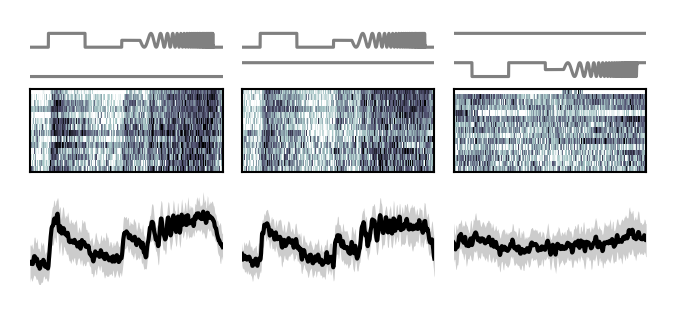

In [18]:
# 0, 313
# 7, 151
rec = 0
nid = 8
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 2

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec06_cell003.pdf


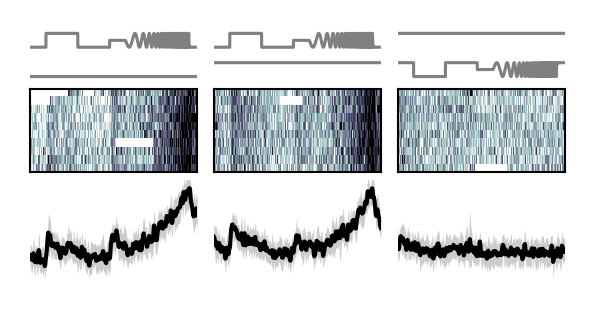

In [19]:
# 0, 279
rec = 6
nid = 3
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 3

Figure saved as /flash/ReiterU/tmp/tomo_FIAWAPCGAFPO/chirp/rec00_cell024.pdf


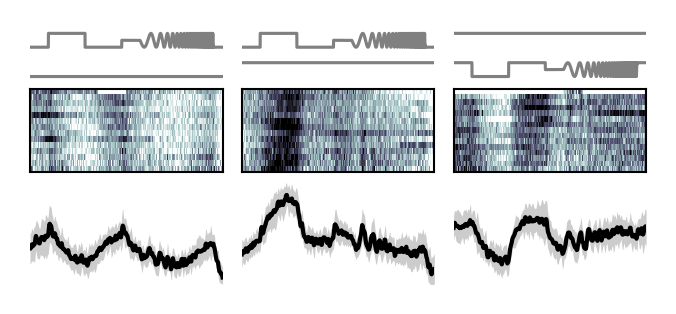

In [78]:
# 0, 80
rec = 0
nid = 24
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 4

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec01_cell174.pdf


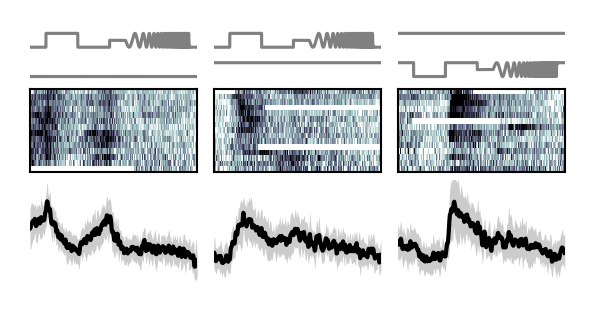

In [21]:
rec = 1
nid = 174
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 5

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec19_cell055.pdf


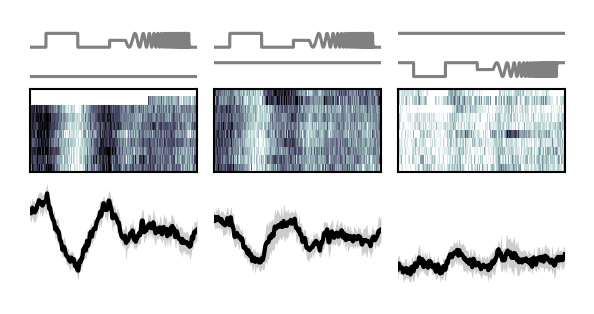

In [22]:
# 4, 114
rec = 19
nid = 55
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 6

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec00_cell033.pdf


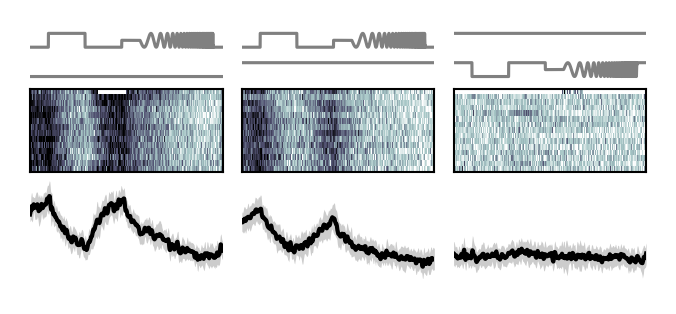

In [23]:
# 0, 33
rec = 0
nid = 33
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 7

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec20_cell190.pdf


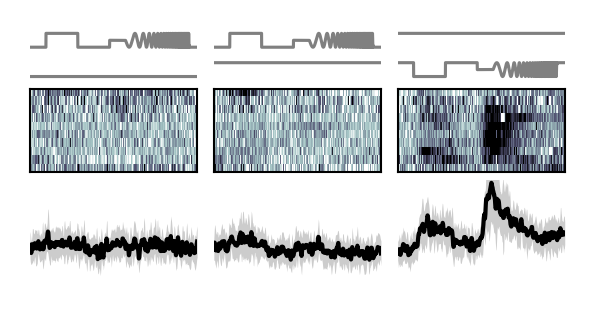

In [26]:
# 5, 63
# 20, 14
# 20, 88
rec = 20
nid = 190
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 8

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec00_cell043.pdf


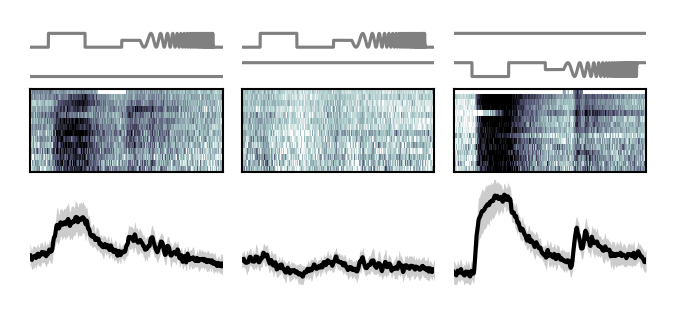

In [27]:
rec = 0
nid = 43
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-1.5, vmax2=3.5, cmap_name="bone_r",
               ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 9

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec14_cell020.pdf


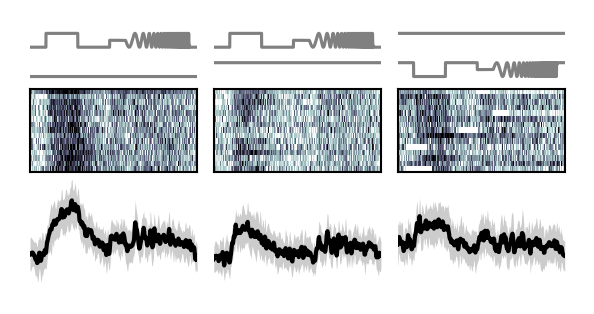

In [28]:
# 11, 6
rec = 14
nid = 20
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 10

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec08_cell008.pdf


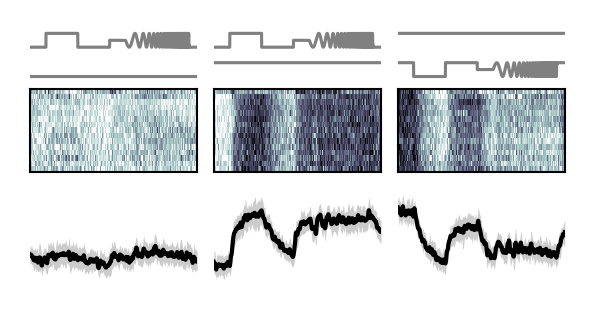

In [29]:
# 0, 107
# 1, 55
# 1, 120
rec = 8
nid = 8
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 11

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec16_cell013.pdf


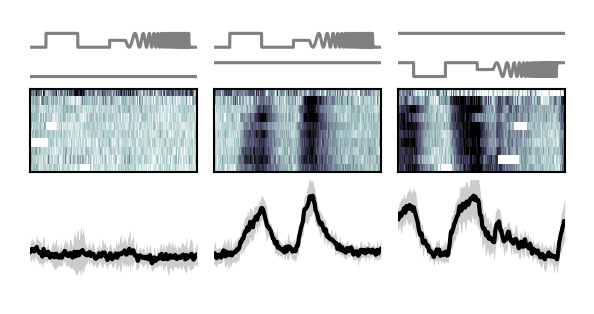

In [30]:
# 0, 137
# 0, 353,
# 6, 18
rec = 16
nid = 13
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 12

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec16_cell034.pdf


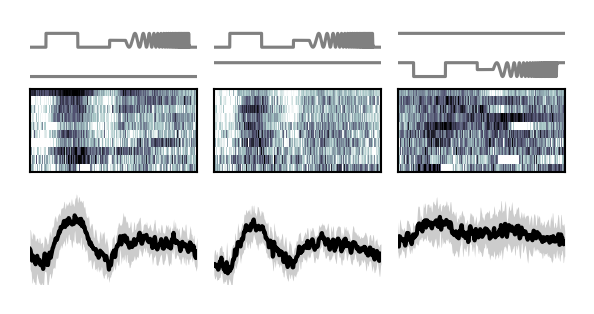

In [32]:
# 3, 108
# 5, 97
rec = 16
nid = 34
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### cluster 13

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec05_cell000.pdf


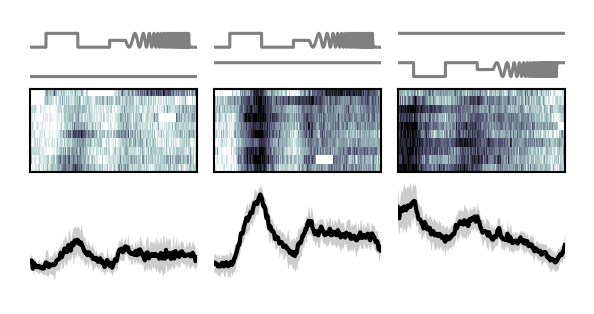

In [33]:
# 0, 54
# 0, 173
rec = 5
nid = 0
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 14

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec15_cell088.pdf


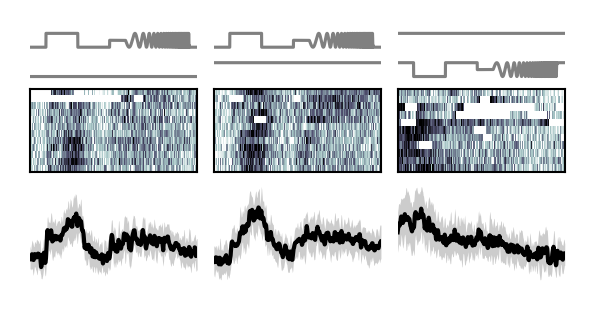

In [34]:
# 15, 65
# 15, 89
rec = 15
nid = 88
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Other interesting cells

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec02_cell049.pdf


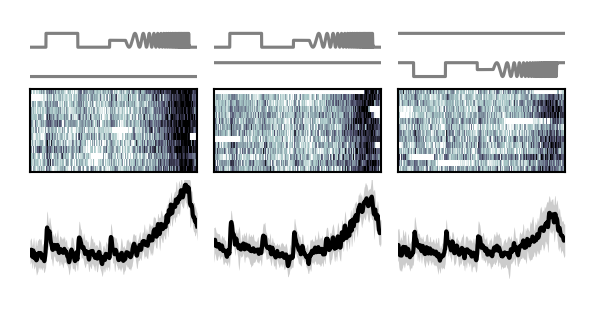

In [35]:
rec = 2
nid = 49
# plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
#                ylabels=False, figsize=(2.65,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

ON-OFF cell?

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec08_cell049.pdf


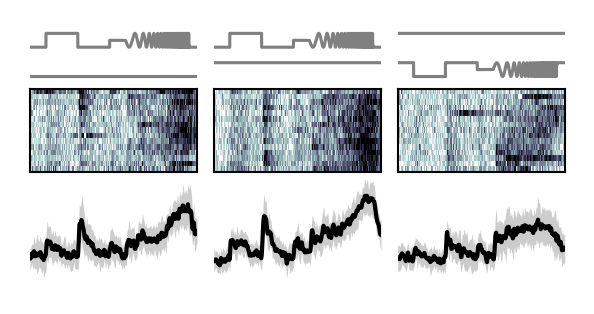

In [36]:
rec = 8
nid = 49
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec13_cell012.pdf


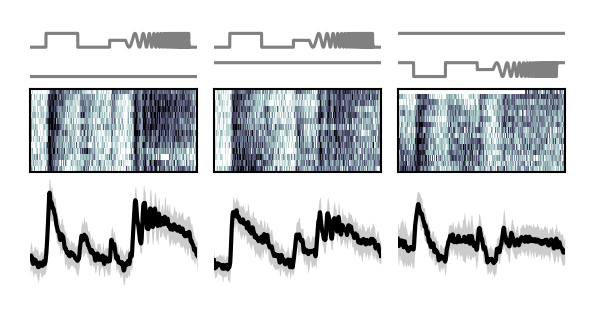

In [37]:
rec = 13
nid = 12
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

OFF cell

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec08_cell045.pdf


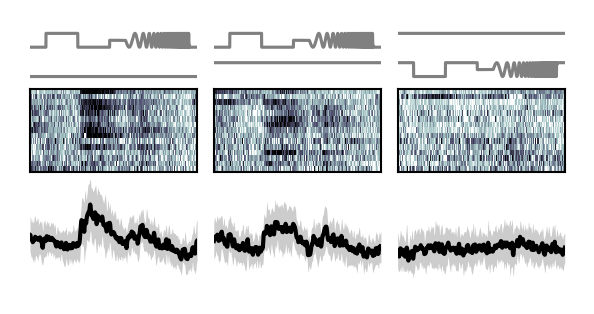

In [38]:
rec = 8
nid = 45
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec11_cell067.pdf


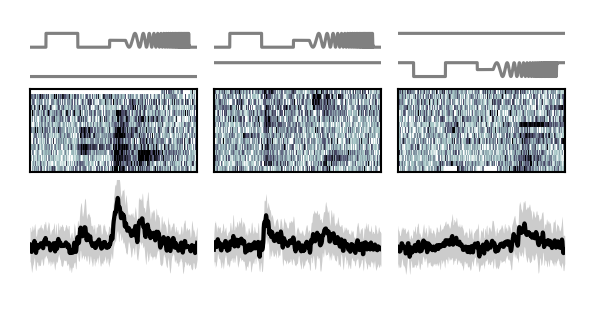

In [39]:
rec = 11
nid = 67
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

DoLP selective

Figure saved as /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/chirp/rec08_cell051.pdf


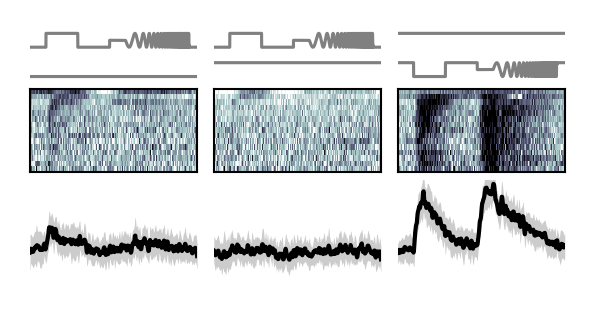

In [43]:
rec = 8
nid = 51
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=2.5, vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=False, figsize=(2.3,1.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Copy data to bucket

In [44]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden_plot"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden_plot
cp -r /flash/ReiterU/tmp/tomo_NLUFBDLYHPEW/* /bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden_plot
